## UDA-Hub：CultPass のカスタマーサポート

問い合わせ（チケット）を受け取り、Classifier が振り分けて、Knowledge／Account／Escalation のどれかが対応する。

```text
load_memory → classifier ─┬─ knowledge ──────────────┬─→ save_memory
                          ├─ account ⇄ account_tools ─┤
                          └─ escalation ←─────────────┘
```

- 短期メモリ：`MemorySaver`（`thread_id` = `ticket_id`）
- 長期メモリ：udahub.db（`ticket_messages`、`ticket_metadata`）
- ログ：`logs/workflow.jsonl`（JSON Lines）

**注意**：このノートブックは udahub.db にデモのチケットを書き込む。元に戻すには `02_core_db_setup.ipynb` を実行し直す。

## Setup

In [1]:
from dotenv import load_dotenv
from utils import chat_interface
from IPython.display import Image, display

load_dotenv()

True

In [2]:
from agentic.workflow import orchestrator, new_ticket

### グラフの構造

In [3]:
# No need to send data to an external service when using Graphviz.

# import shutil
# import subprocess

# graph = orchestrator.get_graph()

# if shutil.which("dot"):
#     # グラフのノードとエッジから DOT（Graphviz の書式）を組み立てる
#     lines = [
#         "digraph G {",
#         '  node [shape=box, style="rounded,filled", fillcolor="#f2f0ff", fontname="Helvetica"];',
#     ]
#     for node_id in graph.nodes:
#         if node_id in ("__start__", "__end__"):
#             lines.append(f'  "{node_id}" [label="{node_id.strip("_")}", shape=oval, fillcolor="white"];')
#     for edge in graph.edges:
#         style = "dashed" if edge.conditional else "solid"  # 点線 = 条件付きエッジ
#         lines.append(f'  "{edge.source}" -> "{edge.target}" [style={style}];')
#     lines.append("}")

#     # ローカルの Graphviz で PNG にして表示する
#     png = subprocess.run(["dot", "-Tpng"], input="\n".join(lines).encode(),
#                          capture_output=True, check=True).stdout
#     display(Image(png))
# else:
#     print(graph.draw_mermaid())

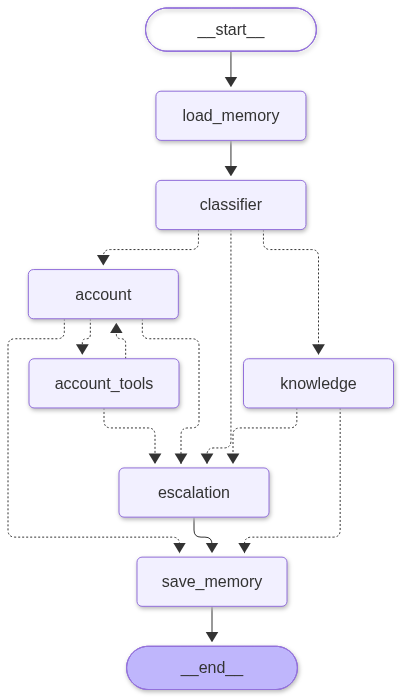

In [4]:
display(
    Image(
        orchestrator.get_graph().draw_mermaid_png(
            # draw_method=MermaidDrawMethod.PYPPETEER
        )
    )
)

### 1 ターン実行するための関数

`chat_interface` と同じ形（`messages` と `thread_id` だけ）でグラフを呼ぶ。`user_id` は、グラフの `load_memory` が `ticket_id` から udahub.db を引いて知る。

In [5]:
from langchain_core.messages import HumanMessage


def ask(ticket_id: str, text: str) -> dict:
    config = {"configurable": {"thread_id": ticket_id}}
    result = orchestrator.invoke({"messages": [HumanMessage(content=text)]}, config=config)
    print(f"User: {text}")
    print(f"  -> category={result['category']}, urgency={result['urgency']}, "
          f"resolution={result['resolution']}")
    if result.get("escalation_reason"):
        print(f"  -> escalation_reason: {result['escalation_reason']}")
    print(f"Assistant: {result['messages'][-1].content}\n")
    return result

## Run

### シナリオ 1：ナレッジ記事で解決する（Knowledge）

In [6]:
ticket_1 = new_ticket("f1f10d")
result = ask(ticket_1, "The QR code won't scan at the museum entrance")
print("Retrieved articles:", result["retrieved_articles"])

User: The QR code won't scan at the museum entrance
  -> category=knowledge, urgency=medium, resolution=resolved
Assistant: Please turn up your screen brightness and open the QR code from “My Reservations” instead of using a screenshot. Also check that your reservation shows as “Confirmed”. If it’s confirmed but the code is still rejected, a support agent will follow up.

Retrieved articles: [{'article_id': '3b2e15ef-cb87-4631-852a-317692df8353', 'title': 'QR Code Not Working at the Venue', 'score': 0.6433}, {'article_id': 'd87f8044-ef78-446e-938c-2177db470084', 'title': 'How to Reserve a Spot for an Event', 'score': 0.3136}, {'article_id': '649859a6-23c0-4cff-801b-530412d35cb2', 'title': "App Crashes or Won't Load", 'score': 0.2554}]


### シナリオ 2：ツールで CultPass DB を照会する（Account）＋ 同じチケットで会話を続ける（短期メモリ）

In [7]:
ticket_2 = new_ticket("f1f10d")
ask(ticket_2, "Is my subscription still active?")
ask(ticket_2, "And how many experiences can I use per month on that plan?");

User: Is my subscription still active?
  -> category=account, urgency=low, resolution=resolved
Assistant: Yes — your subscription is still active. It’s a premium plan.

User: And how many experiences can I use per month on that plan?
  -> category=account, urgency=low, resolution=resolved
Assistant: Your premium plan includes 2 experiences per month.



### シナリオ 3：記事が人への引き継ぎを指示している（Knowledge → Escalation）＋ 長期メモリ

同じユーザー（`f1f10d`）の新しいチケット。`past_context` に、シナリオ 1、2 のチケットが出る。

In [8]:
ticket_3 = new_ticket("f1f10d")
result = ask(ticket_3, "I was charged twice this month")
print("Past context:\n" + result["past_context"])
print("\nHandoff summary:\n" + result["handoff_summary"])

User: I was charged twice this month
  -> category=knowledge, urgency=medium, resolution=escalated
  -> escalation_reason: The customer reports a duplicate charge for the same period, which the article says must be escalated to human support.
Assistant: You can review all charges under “My Account” > “Billing History”. Your subscription renews monthly, and premium event fees are charged separately. Since you were charged twice for the same period, I’m forwarding this to our billing team right away, and a support agent will follow up.

Thanks for letting us know. Our team needs to review your request, and a member of our support team will follow up with you soon.

Past context:
Past tickets from this customer (newest first):
- 2026-11-14 [resolved] account (urgency:low): "Is my subscription still active?" → "Your premium plan includes 2 experiences per month."
- 2026-11-14 [resolved] knowledge (urgency:medium): "The QR code won't scan at the museum entrance" → "Please turn up your scree

### シナリオ 4：ブロック済みのユーザーが予約のキャンセルを依頼する（Account → Escalation）

In [9]:
ticket_4 = new_ticket("a4ab87")
ask(ticket_4, "Please cancel my booking for next week");

User: Please cancel my booking for next week
  -> category=account, urgency=medium, resolution=escalated
  -> escalation_reason: User account is blocked
Assistant: Thanks for reaching out. A member of our support team will follow up to review your request and help with the cancellation.



### シナリオ 5：記事にない質問（信頼度が低い）と、人を求める問い合わせ（Escalation）

In [10]:
ticket_5 = new_ticket("88382b")
ask(ticket_5, "Do you sell gift cards?");

User: Do you sell gift cards?
  -> category=knowledge, urgency=low, resolution=escalated
  -> escalation_reason: Low knowledge confidence (0.22 < 0.3)
Assistant: Thanks for your message. Our team needs to review your request, and a member of our support team will follow up shortly.



In [11]:
ticket_6 = new_ticket("88382b")
ask(ticket_6, "責任者と話をさせてください。もう我慢できません。");

User: 責任者と話をさせてください。もう我慢できません。
  -> category=escalation, urgency=high, resolution=escalated
  -> escalation_reason: The customer explicitly asks to speak with a responsible person and expresses strong frustration, so a human should handle it immediately.
Assistant: ご不快な思いをおかけして申し訳ありません。担当チームがご要望を確認し、サポート担当者からご連絡いたします。



## 確認

### 短期メモリ：チケットの State（ツールの呼び出しも含む）

In [12]:
list(orchestrator.get_state_history(
    config = {
        "configurable": {
            "thread_id": ticket_2,
        }
    }
))[0].values["messages"]

[HumanMessage(content='Is my subscription still active?', additional_kwargs={}, response_metadata={}, id='19ef6c82-31b2-4568-8671-960cfeb9aa2a'),
 AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 488, 'total_tokens': 510, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini-2026-03-17', 'system_fingerprint': None, 'id': 'chatcmpl-Ek7V4GY0NzL65y7f48omBqGZcDl3C', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, name='account_agent', id='lc_run--01a1da1b-ee48-7681-89ac-f0ed54f30427-0', tool_calls=[{'name': 'get_subscription', 'args': {'user_id': 'f1f10d'}, 'id': 'call_MMMe5qa5yyev

### 長期メモリ：udahub.db に保存されたチケットの結果

In [13]:
from agentic.tools.memory import get_ticket_info

for t in [ticket_1, ticket_2, ticket_3, ticket_4, ticket_5, ticket_6]:
    info = get_ticket_info(t)["data"]
    print(info["external_user_id"], info["status"], info["main_issue_type"], info["tags"])
    

f1f10d resolved knowledge urgency:medium
f1f10d resolved account urgency:low
f1f10d escalated knowledge urgency:medium
a4ab87 escalated account urgency:medium
88382b escalated knowledge urgency:low
88382b escalated escalation urgency:high


### ログ（JSON Lines）：シナリオ 3 の流れ

In [14]:
from agentic.logging_utils import read_logs

for record in read_logs(ticket_3):
    print(record)
    

{'ts': '2026-11-14T21:50:32', 'ticket_id': '72039b2f-7798-440a-b436-646c654736cf', 'node': 'load_memory', 'event': 'memory_loaded', 'user_id': 'f1f10d', 'past_tickets': 3, 'error': None}
{'ts': '2026-11-14T21:50:33', 'ticket_id': '72039b2f-7798-440a-b436-646c654736cf', 'node': 'classifier', 'event': 'classified', 'category': 'knowledge', 'urgency': 'medium', 'reason': 'This is a billing/charge question, which is handled as knowledge because it does not require the customer’s account data.'}
{'ts': '2026-11-14T21:50:35', 'ticket_id': '72039b2f-7798-440a-b436-646c654736cf', 'node': 'knowledge', 'event': 'retrieved', 'top_article': 'Unexpected or Duplicate Charges', 'confidence': 0.5885, 'escalation_reason': 'The customer reports a duplicate charge for the same period, which the article says must be escalated to human support.'}
{'ts': '2026-11-14T21:50:37', 'ticket_id': '72039b2f-7798-440a-b436-646c654736cf', 'node': 'escalation', 'event': 'escalated', 'reason': 'The customer reports a d

In [ ]:
# raise SystemExit("Stop here")

## 対話モード

`quit` で終了する。

In [15]:
chat_interface(orchestrator, new_ticket("f1f10d"))

User: quit
Assistant: Goodbye!
